# Machine Learning Project |  Milestone 1: Exploratory Data Analysis (EDA)

## Environment Setup and Data Loading

In [29]:
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset'] = 'cm'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10

file_path = 'H2.csv'
if not os.path.exists(file_path):
    if os.path.exists('/content/H2.csv'):
        file_path = '/content/H2.csv'
    else:
        url = 'https://raw.githubusercontent.com/afaq-ahmad/Hotel-booking-demand-Case-Study/master/H2.csv'
        urllib.request.urlretrieve(url, 'H2.csv')
        file_path = 'H2.csv'

df = pd.read_csv(file_path)
print(f'Dataset successfully loaded from: {file_path}')
print(f'Total records: {df.shape[0]:,}')
print(f'Total variables: {df.shape[1]}')

Dataset successfully loaded from: H2.csv
Total records: 79,330
Total variables: 31


## Dataset properties

In [30]:
schema_df = pd.DataFrame({
    'Column': df.columns,
    'Non-Null Count': df.notnull().sum().values,
    'Null Count': df.isnull().sum().values,
    'Null Pct (%)': np.round(df.isnull().mean().values * 100, 2),
    'Data Type': df.dtypes.astype(str).values,
    'Distinct Values': df.nunique().values,
    'Sample Value': [df[col].dropna().iloc[0] if len(df[col].dropna()) > 0 else 'N/A' for col in df.columns]
})
display(schema_df)
print(f'Memory usage: {df.memory_usage(deep=True).sum() / (1024 * 1024):.2f} MB')

,Column,Non-Null Count,Null Count,Null Pct (%),Data Type,Distinct Values,Sample Value
0,IsCanceled,79330,0,0.00,int64,2,0
1,LeadTime,79330,0,0.00,int64,453,6
2,ArrivalDateYear,79330,0,0.00,int64,3,2015
3,ArrivalDateMonth,79330,0,0.00,object,12,July
4,ArrivalDateWeekNumber,79330,0,0.00,int64,53,27
5,ArrivalDateDayOfMonth,79330,0,0.00,int64,31,1
6,StaysInWeekendNights,79330,0,0.00,int64,14,0
7,StaysInWeekNights,79330,0,0.00,int64,29,2
8,Adults,79330,0,0.00,int64,5,1
9,Children,79326,4,0.01,float64,4,0.0


Memory usage: 68.93 MB


## Data Quality / Missing Values

In [31]:
string_cols = df.select_dtypes(include=['object']).columns
for col in string_cols:
    df[col] = df[col].astype(str).str.strip()

explicit_nulls = df.isnull().sum()[df.isnull().sum() > 0]
sentinel_nulls = {}
for col in string_cols:
    null_count = (df[col] == 'NULL').sum()
    if null_count > 0:
        sentinel_nulls[col] = null_count

quality_data = []
for col in set(list(explicit_nulls.index) + list(sentinel_nulls.keys())):
    exp = explicit_nulls.get(col, 0)
    sen = sentinel_nulls.get(col, 0)
    tot = exp + sen
    pct = (tot / len(df)) * 100
    quality_data.append({'Variable': col, 'Explicit NaNs': exp, 'Sentinel NULLs': sen, 'Total Missing': tot, 'Missing Pct (%)': np.round(pct, 2)})

quality_df = pd.DataFrame(quality_data).sort_values(by='Total Missing', ascending=False)
display(quality_df)

num_duplicates = df.duplicated().sum()
pct_duplicates = (num_duplicates / len(df)) * 100
print(f'Identical row duplicates: {num_duplicates:,} ({pct_duplicates:.2f}%)')

zero_guests = ((df['Adults'] == 0) & (df['Children'] == 0) & (df['Babies'] == 0)).sum()
print(f'Zero-guest records (Adults + Children + Babies == 0): {zero_guests} ({(zero_guests / len(df)) * 100:.3f}%)')

zero_nights = ((df['StaysInWeekendNights'] == 0) & (df['StaysInWeekNights'] == 0)).sum()
print(f'Zero-night stays (Weekend + Week nights == 0): {zero_nights} ({(zero_nights / len(df)) * 100:.2f}%)')

,Variable,Explicit NaNs,Sentinel NULLs,Total Missing,Missing Pct (%)
2,Company,0,75641,75641,95.35
0,Agent,0,8131,8131,10.25
1,Children,4,0,4,0.01


Identical row duplicates: 25,902 (32.65%)
Zero-guest records (Adults + Children + Babies == 0): 167 (0.211%)
Zero-night stays (Weekend + Week nights == 0): 331 (0.42%)


## Univariate Distributions (Statistical analysis)

In [32]:
num_cols = df.select_dtypes(include=[np.number]).columns
desc_stats = df[num_cols].describe().T
desc_stats['skewness'] = df[num_cols].skew()
desc_stats['kurtosis'] = df[num_cols].kurtosis()
desc_stats = desc_stats[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'skewness', 'kurtosis']]
desc_stats = np.round(desc_stats, 2)
display(desc_stats)

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
IsCanceled,79330.0,0.42,0.49,0.0,0.0,0.0,1.0,1.0,0.34,-1.89
LeadTime,79330.0,109.74,110.95,0.0,23.0,74.0,163.0,629.0,1.39,1.80
ArrivalDateYear,79330.0,2016.17,0.70,2015.0,2016.0,2016.0,2017.0,2017.0,-0.25,-0.95
ArrivalDateWeekNumber,79330.0,27.18,13.40,1.0,17.0,27.0,38.0,53.0,-0.01,-0.96
ArrivalDateDayOfMonth,79330.0,15.79,8.73,1.0,8.0,16.0,23.0,31.0,-0.01,-1.18
StaysInWeekendNights,79330.0,0.80,0.89,0.0,0.0,1.0,2.0,16.0,1.13,5.00
StaysInWeekNights,79330.0,2.18,1.46,0.0,1.0,2.0,3.0,41.0,2.96,32.49
Adults,79330.0,1.85,0.51,0.0,2.0,2.0,2.0,4.0,-0.43,1.11
Children,79326.0,0.09,0.37,0.0,0.0,0.0,0.0,3.0,4.34,18.78
Babies,79330.0,0.00,0.08,0.0,0.0,0.0,0.0,10.0,44.78,4229.92


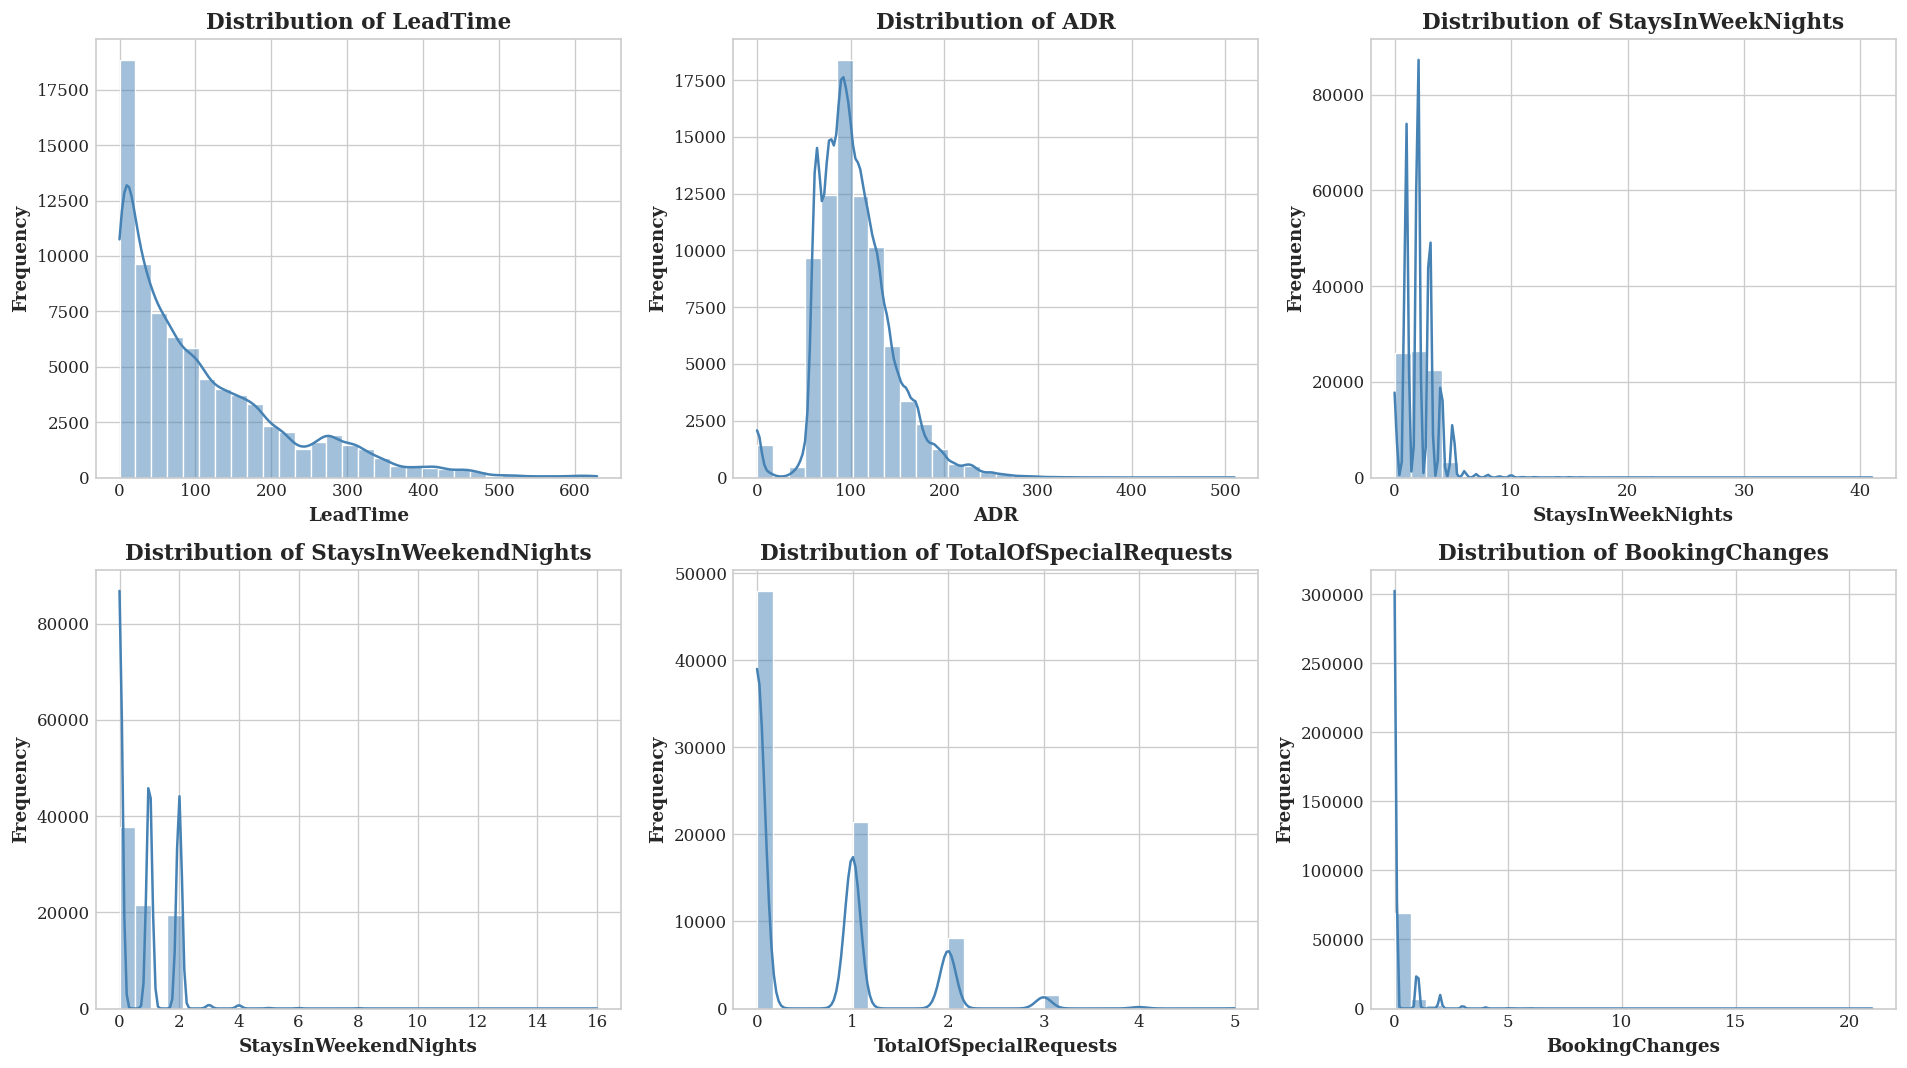

In [33]:
key_num_vars = ['LeadTime', 'ADR', 'StaysInWeekNights', 'StaysInWeekendNights', 'TotalOfSpecialRequests', 'BookingChanges']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, var in enumerate(key_num_vars):
    val_series = df[var].dropna()
    if var == 'ADR':
        val_series = val_series[val_series < 1000]
    sns.histplot(val_series, ax=axes[i], kde=True, color='steelblue', bins=30, edgecolor='white')
    axes[i].set_title(f'Distribution of {var}')
    axes[i].set_xlabel(var)
    axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

## Target Variable Analysis #1 (Cancellation Behavior / Classification Target)

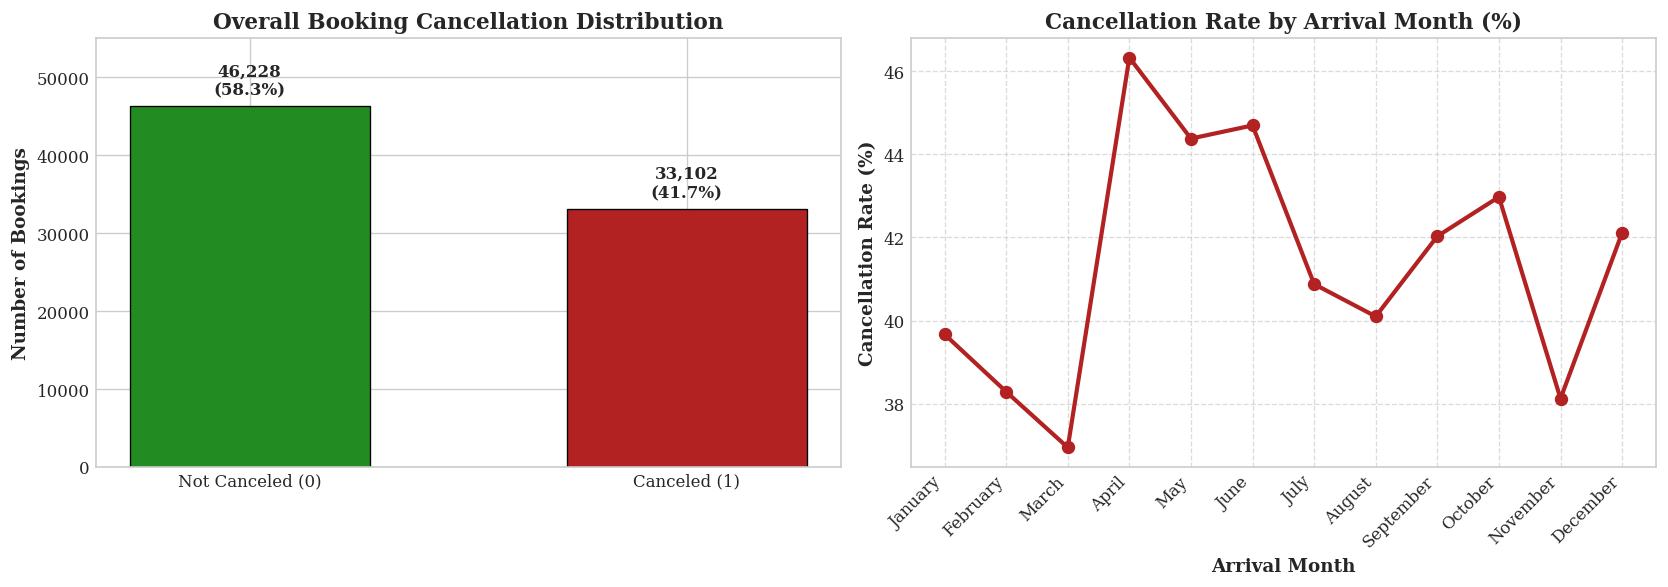

Not Canceled: 46,228 (58.27%)
Canceled: 33,102 (41.73%)


In [34]:
cancel_counts = df['IsCanceled'].value_counts()
cancel_pcts = df['IsCanceled'].value_counts(normalize=True) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

bars = ax1.bar(['Not Canceled (0)', 'Canceled (1)'], cancel_counts.values, color=['forestgreen', 'firebrick'], width=0.55, edgecolor='black', linewidth=0.8)
for bar in bars:
    height = bar.get_height()
    pct = (height / len(df)) * 100
    ax1.text(bar.get_x() + bar.get_width() / 2, height + 1000, f'{height:,}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax1.set_title('Overall Booking Cancellation Distribution')
ax1.set_ylabel('Number of Bookings')
ax1.set_ylim(0, 55000)

month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
monthly_cancel = df.groupby('ArrivalDateMonth')['IsCanceled'].mean().reindex(month_order) * 100
ax2.plot(range(len(month_order)), monthly_cancel.values, marker='o', color='firebrick', linewidth=2.5, markersize=7)
ax2.set_title('Cancellation Rate by Arrival Month (%)')
ax2.set_xlabel('Arrival Month')
ax2.set_ylabel('Cancellation Rate (%)')
ax2.set_xticks(range(len(month_order)))
ax2.set_xticklabels(month_order, rotation=45, ha='right')
ax2.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

print(f'Not Canceled: {cancel_counts[0]:,} ({cancel_pcts[0]:.2f}%)')
print(f'Canceled: {cancel_counts[1]:,} ({cancel_pcts[1]:.2f}%)')

## Target Variable Analysis #2 (Average Daily Rate / Regression Target)

/tmp/ipykernel_1030/1981778317.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=customer_adr.index, y=customer_adr.values, ax=ax2, palette='Blues_r')


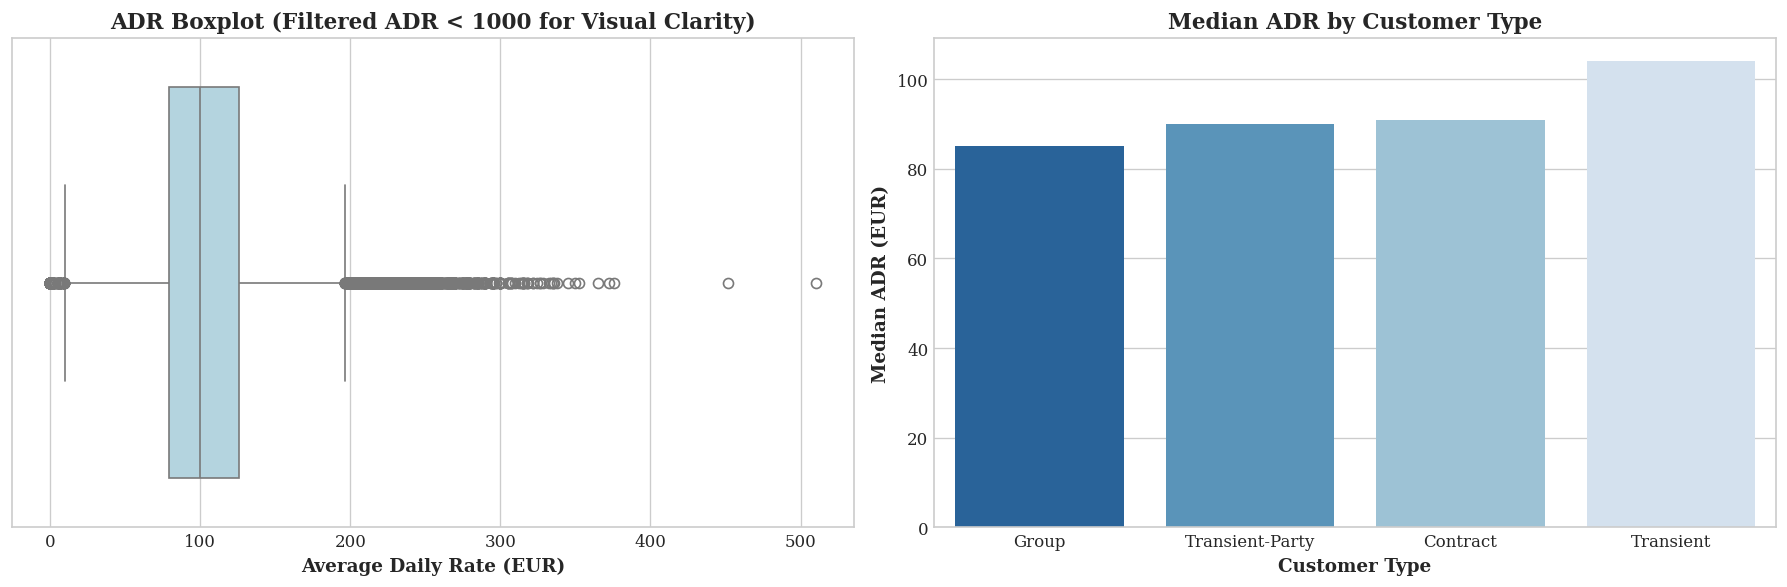

ADR Mean: 105.30, Median: 99.90, Std: 43.60
ADR Min: 0.00, Max: 5400.00
Interquartile Range (IQR): [79.20, 126.00], Length: 46.80
Tukey Outlier Bounds: [9.00, 196.20]
Number of Outliers: 3,387 (4.27%)
Zero-Rate Bookings (ADR == 0): 1,208 (1.52%)


In [35]:
q25, q50, q75 = df['ADR'].quantile([0.25, 0.5, 0.75])
iqr = q75 - q25
lower_bound = q25 - 1.5 * iqr
upper_bound = q75 + 1.5 * iqr
outliers = df[(df['ADR'] < lower_bound) | (df['ADR'] > upper_bound)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(x=df[df['ADR'] < 1000]['ADR'], ax=ax1, color='lightblue')
ax1.set_title('ADR Boxplot (Filtered ADR < 1000 for Visual Clarity)')
ax1.set_xlabel('Average Daily Rate (EUR)')

customer_adr = df[df['ADR'] < 1000].groupby('CustomerType')['ADR'].median().sort_values()
sns.barplot(x=customer_adr.index, y=customer_adr.values, ax=ax2, palette='Blues_r')
ax2.set_title('Median ADR by Customer Type')
ax2.set_xlabel('Customer Type')
ax2.set_ylabel('Median ADR (EUR)')

plt.tight_layout()
plt.show()

print(f'ADR Mean: {df["ADR"].mean():.2f}, Median: {q50:.2f}, Std: {df["ADR"].std():.2f}')
print(f'ADR Min: {df["ADR"].min():.2f}, Max: {df["ADR"].max():.2f}')
print(f'Interquartile Range (IQR): [{q25:.2f}, {q75:.2f}], Length: {iqr:.2f}')
print(f'Tukey Outlier Bounds: [{lower_bound:.2f}, {upper_bound:.2f}]')
print(f'Number of Outliers: {len(outliers):,} ({(len(outliers) / len(df)) * 100:.2f}%)')
print(f'Zero-Rate Bookings (ADR == 0): {(df["ADR"] == 0).sum():,} ({((df["ADR"] == 0).sum() / len(df)) * 100:.2f}%)')

## Bivariate and Multivariate Relationships


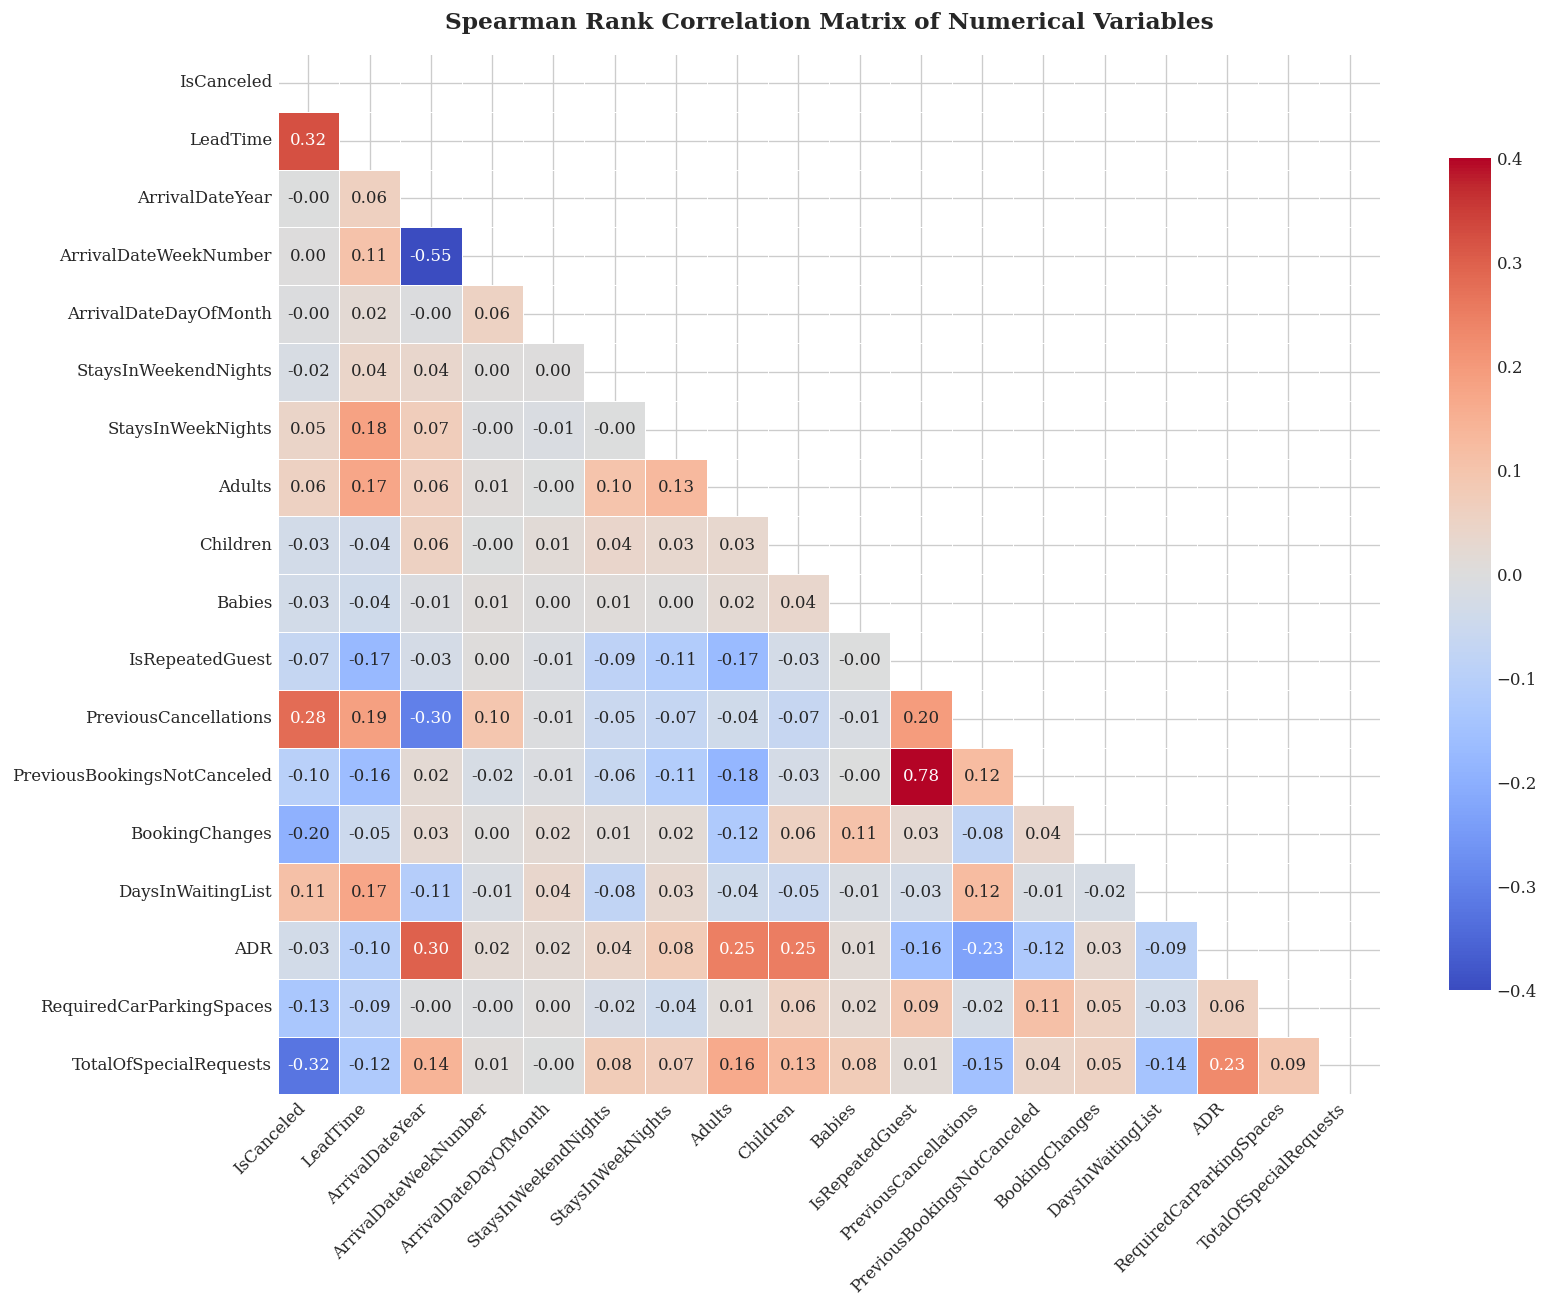

,Spearman Correlation with IsCanceled
LeadTime,0.325
PreviousCancellations,0.280
DaysInWaitingList,0.112
Adults,0.056
StaysInWeekNights,0.046
ArrivalDateWeekNumber,0.001
ArrivalDateYear,-0.001
ArrivalDateDayOfMonth,-0.004
StaysInWeekendNights,-0.018
ADR,-0.031


In [36]:
corr_vars = [
    'IsCanceled', 'LeadTime', 'ArrivalDateYear', 'ArrivalDateWeekNumber',
    'ArrivalDateDayOfMonth', 'StaysInWeekendNights', 'StaysInWeekNights',
    'Adults', 'Children', 'Babies', 'IsRepeatedGuest',
    'PreviousCancellations', 'PreviousBookingsNotCanceled',
    'BookingChanges', 'DaysInWaitingList', 'ADR',
    'RequiredCarParkingSpaces', 'TotalOfSpecialRequests'
]

corr_matrix = df[corr_vars].corr(method='spearman')

plt.figure(figsize=(14, 11))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, cmap='coolwarm', vmin=-0.4, vmax=0.4, center=0, annot=True, fmt='.2f', linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Spearman Rank Correlation Matrix of Numerical Variables', fontsize=14, weight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

top_corr_cancel = corr_matrix['IsCanceled'].drop('IsCanceled').sort_values(ascending=False)
display(pd.DataFrame({'Spearman Correlation with IsCanceled': np.round(top_corr_cancel, 3)}))

/tmp/ipykernel_1030/521335543.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=group, x=col, y='CancelRate', ax=axes[i], palette='viridis')
/tmp/ipykernel_1030/521335543.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=group, x=col, y='CancelRate', ax=axes[i], palette='viridis')
/tmp/ipykernel_1030/521335543.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=group, x=col, y='CancelRate', ax=axes[i], palette='viridis')
/tmp/ipykernel_1030/521335543.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is d

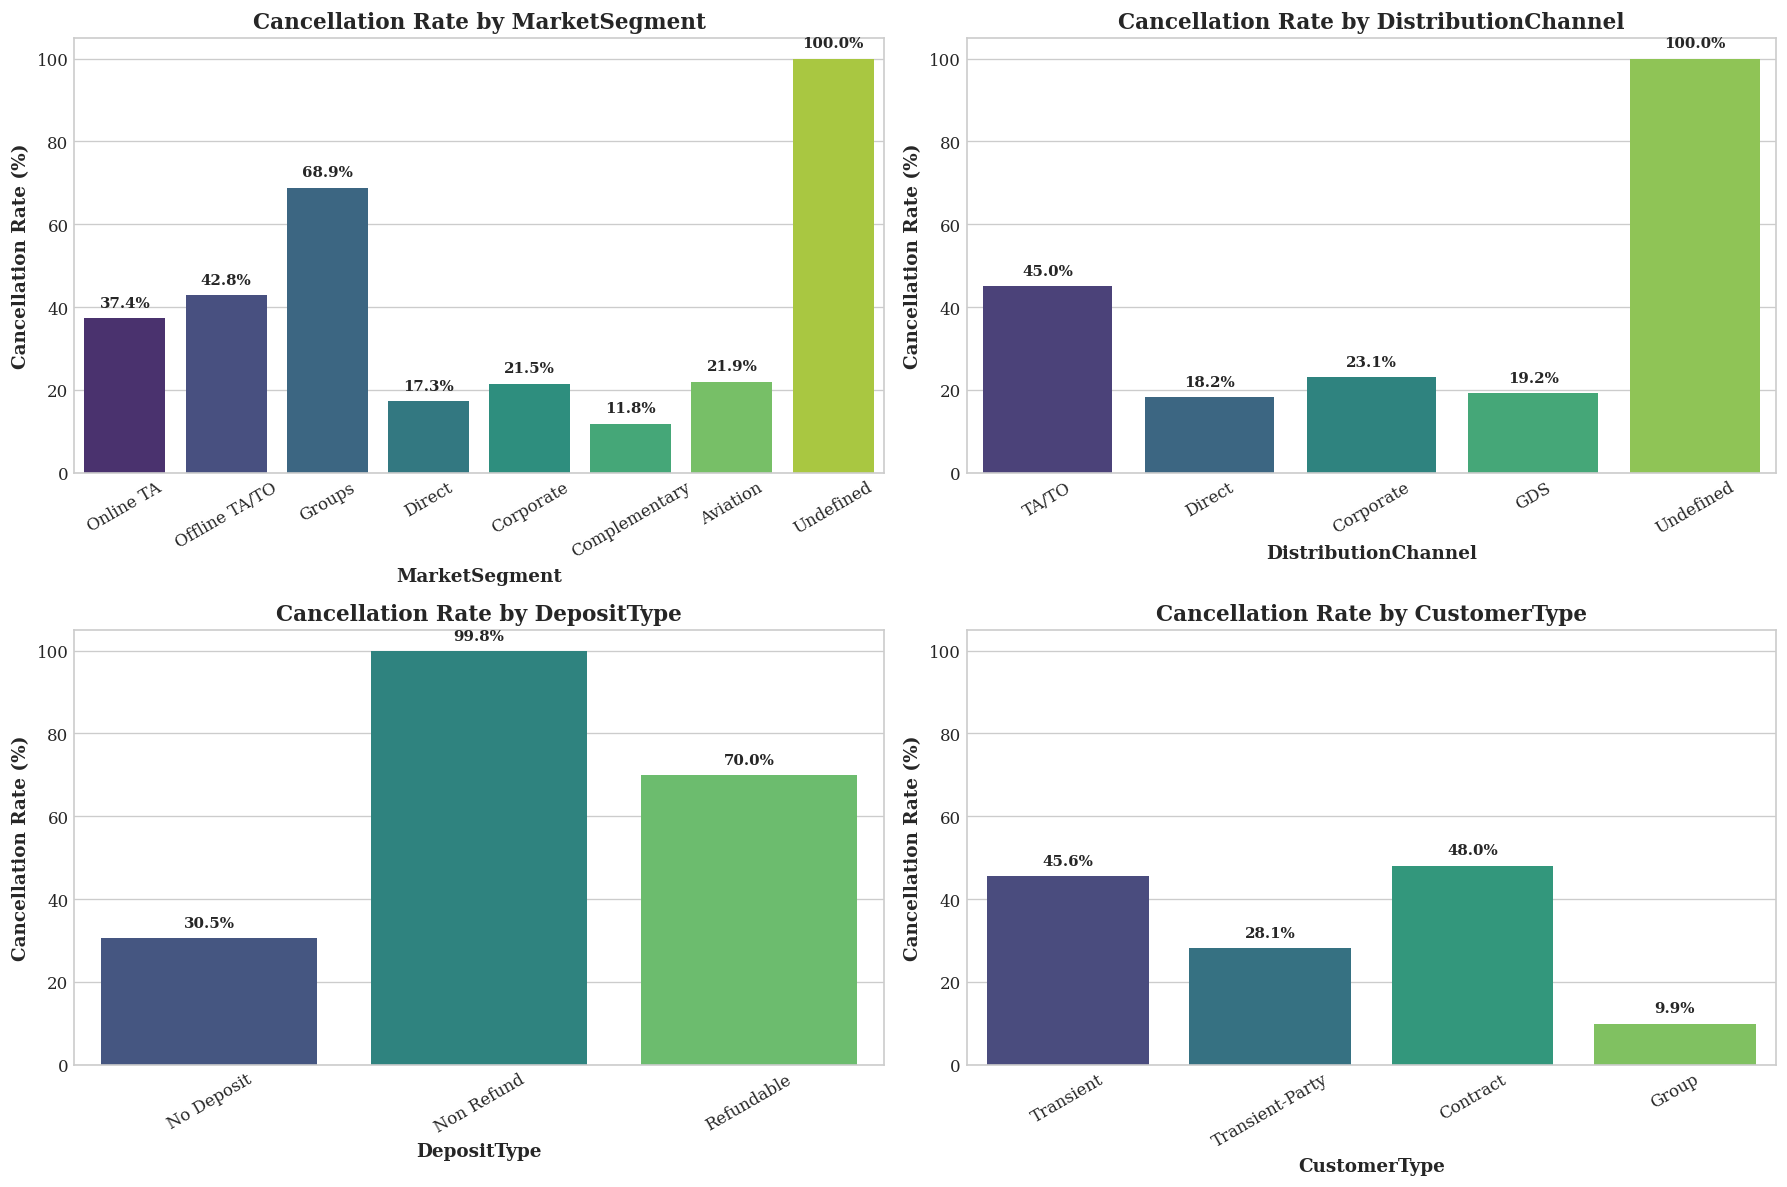

,Total_Bookings,Canceled_Bookings,Cancel_Rate_Pct
DepositType,,,
No Deposit,66442,20244,30.47
Non Refund,12868,12844,99.81
Refundable,20,14,70.00


In [37]:
cat_features = ['MarketSegment', 'DistributionChannel', 'DepositType', 'CustomerType']

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(cat_features):
    group = df.groupby(col).agg(Total=('IsCanceled', 'count'), CancelRate=('IsCanceled', 'mean')).reset_index()
    group['CancelRate'] = group['CancelRate'] * 100
    group = group.sort_values(by='Total', ascending=False)

    sns.barplot(data=group, x=col, y='CancelRate', ax=axes[i], palette='viridis')
    axes[i].set_title(f'Cancellation Rate by {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Cancellation Rate (%)')
    axes[i].tick_params(axis='x', rotation=30)
    axes[i].set_ylim(0, 105)

    for p in axes[i].patches:
        axes[i].annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height() + 2), ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

deposit_summary = df.groupby('DepositType').agg(
    Total_Bookings=('IsCanceled', 'count'),
    Canceled_Bookings=('IsCanceled', 'sum'),
    Cancel_Rate_Pct=('IsCanceled', lambda x: np.round(x.mean() * 100, 2))
)
display(deposit_summary)

/tmp/ipykernel_1030/3557437173.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='IsCanceled', y='LeadTime', ax=axes[0], palette=['forestgreen', 'firebrick'])
/tmp/ipykernel_1030/3557437173.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Not Canceled (0)', 'Canceled (1)'])


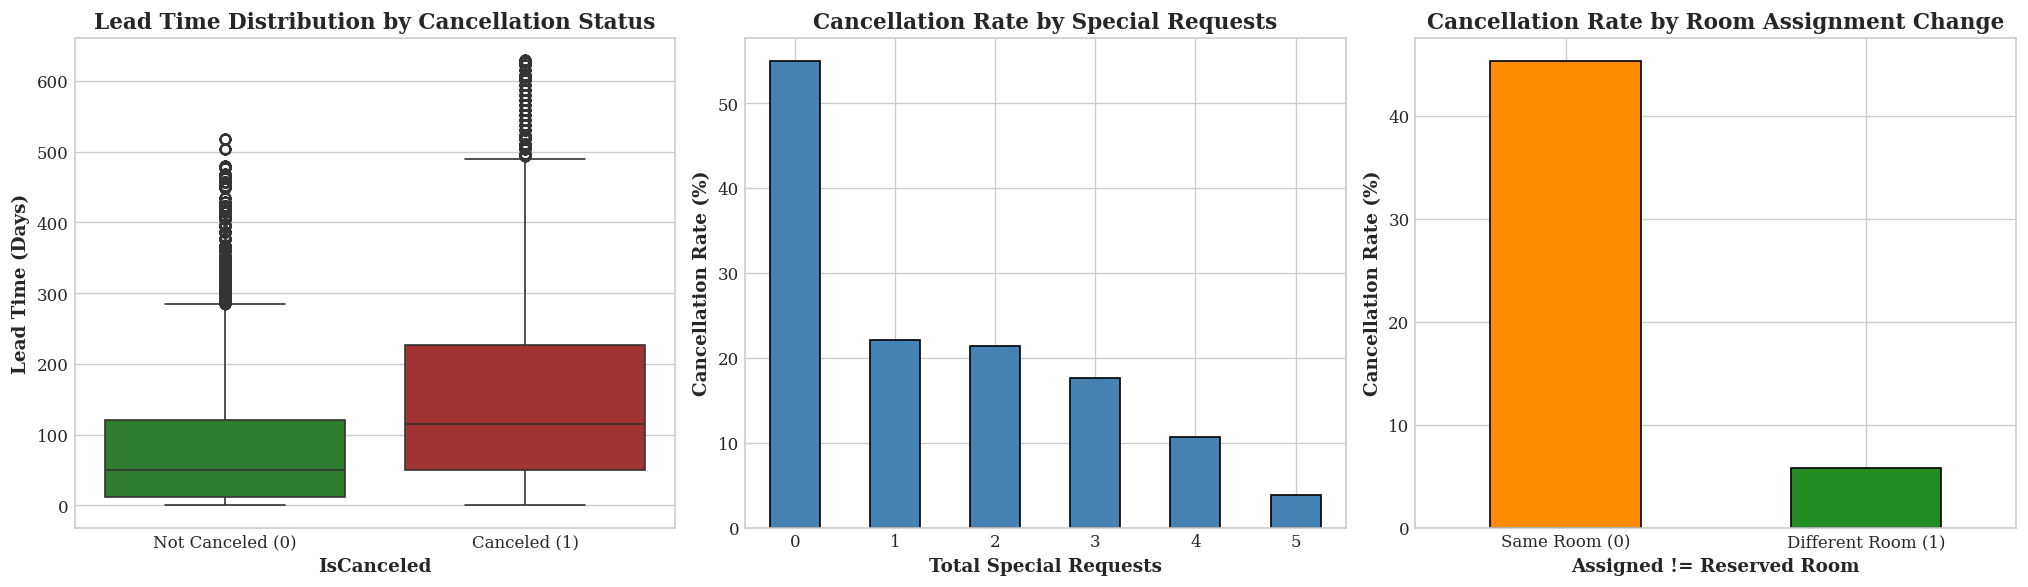

Mean Lead Time for Not Canceled: 80.7 days (Median: 50.0)
Mean Lead Time for Canceled: 150.3 days (Median: 115.0)
Discrepancy rate (Assigned != Reserved): 9.07%


In [38]:
df['RoomTypeDiscrepancy'] = (df['ReservedRoomType'] != df['AssignedRoomType']).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.boxplot(data=df, x='IsCanceled', y='LeadTime', ax=axes[0], palette=['forestgreen', 'firebrick'])
axes[0].set_title('Lead Time Distribution by Cancellation Status')
axes[0].set_xticklabels(['Not Canceled (0)', 'Canceled (1)'])
axes[0].set_ylabel('Lead Time (Days)')

requests_cancel = df.groupby('TotalOfSpecialRequests')['IsCanceled'].mean() * 100
requests_cancel.plot(kind='bar', ax=axes[1], color='steelblue', edgecolor='black')
axes[1].set_title('Cancellation Rate by Special Requests')
axes[1].set_xlabel('Total Special Requests')
axes[1].set_ylabel('Cancellation Rate (%)')
axes[1].tick_params(axis='x', rotation=0)

room_cancel = df.groupby('RoomTypeDiscrepancy')['IsCanceled'].mean() * 100
room_cancel.plot(kind='bar', ax=axes[2], color=['darkorange', 'forestgreen'], edgecolor='black')
axes[2].set_title('Cancellation Rate by Room Assignment Change')
axes[2].set_xlabel('Assigned != Reserved Room')
axes[2].set_xticklabels(['Same Room (0)', 'Different Room (1)'], rotation=0)
axes[2].set_ylabel('Cancellation Rate (%)')

plt.tight_layout()
plt.show()

print(f'Mean Lead Time for Not Canceled: {df[df["IsCanceled"] == 0]["LeadTime"].mean():.1f} days (Median: {df[df["IsCanceled"] == 0]["LeadTime"].median():.1f})')
print(f'Mean Lead Time for Canceled: {df[df["IsCanceled"] == 1]["LeadTime"].mean():.1f} days (Median: {df[df["IsCanceled"] == 1]["LeadTime"].median():.1f})')
print(f'Discrepancy rate (Assigned != Reserved): {df["RoomTypeDiscrepancy"].mean() * 100:.2f}%')

## Direct and Indirect Target Leakage Audit

In [39]:
leakage_crosstab = pd.crosstab(df['ReservationStatus'], df['IsCanceled'], margins=True)
display(leakage_crosstab)

perfect_leakage = (
    ((df['ReservationStatus'] == 'Check-Out') & (df['IsCanceled'] == 0)).sum() +
    ((df['ReservationStatus'].isin(['Canceled', 'No-Show'])) & (df['IsCanceled'] == 1)).sum()
)
print(f'Exact mathematical consistency: {perfect_leakage} / {len(df)} ({(perfect_leakage / len(df)) * 100:.1f}%)')

IsCanceled,0,1,All
ReservationStatus,,,
Canceled,0,32186,32186
Check-Out,46228,0,46228
No-Show,0,916,916
All,46228,33102,79330


Exact mathematical consistency: 79330 / 79330 (100.0%)


## Feature Associations for Customer Segmentation (Clustering)

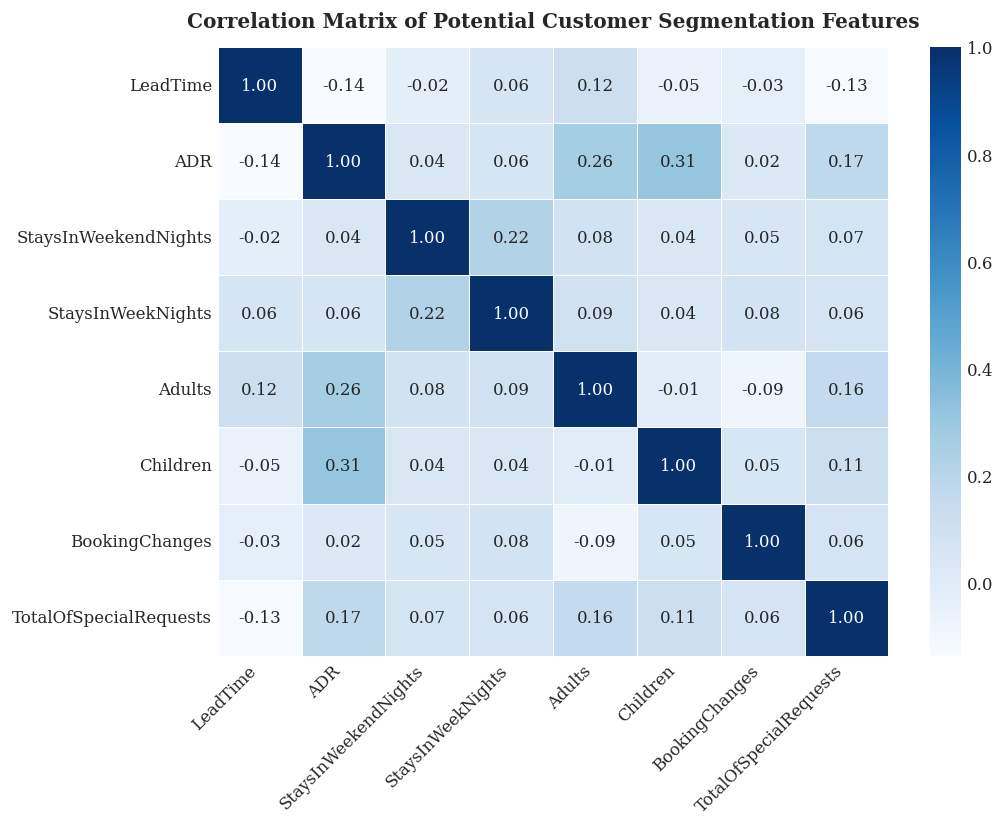

,mean,std,min,median,max
LeadTime,109.74,110.95,0.0,74.0,629.0
ADR,105.30,43.60,0.0,99.9,5400.0
StaysInWeekendNights,0.80,0.89,0.0,1.0,16.0
StaysInWeekNights,2.18,1.46,0.0,2.0,41.0
Adults,1.85,0.51,0.0,2.0,4.0
Children,0.09,0.37,0.0,0.0,3.0
BookingChanges,0.19,0.61,0.0,0.0,21.0
TotalOfSpecialRequests,0.55,0.78,0.0,0.0,5.0


In [40]:
cluster_features = [
    'LeadTime', 'ADR', 'StaysInWeekendNights', 'StaysInWeekNights',
    'Adults', 'Children', 'BookingChanges', 'TotalOfSpecialRequests'
]

cluster_corr = df[cluster_features].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(cluster_corr, annot=True, fmt='.2f', cmap='Blues', cbar=True, linewidths=0.5)
plt.title('Correlation Matrix of Potential Customer Segmentation Features', fontsize=12, weight='bold', pad=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

cluster_summary = df[cluster_features].agg(['mean', 'std', 'min', 'median', 'max']).T
display(np.round(cluster_summary, 2))